# **Cell 1: Install Dependencies**

In [21]:
!pip install -q kagglehub imbalanced-learn xgboost lightgbm catboost scikit-learn

# **Cell 2: Load Dataset from Kaggle (No Token)**

In [44]:
import kagglehub, os, pandas as pd

path = kagglehub.dataset_download("rabieelkharoua/alzheimers-disease-dataset")
csv_path = None
for root, _, files in os.walk(path):
    for f in files:
        if f.endswith(".csv"):
            csv_path = os.path.join(root, f)
            break

df = pd.read_csv(csv_path)
print(f"Shape: {df.shape}")
print(f"Target:\n{df['Diagnosis'].value_counts()}")
print(f"Missing: {df.isnull().sum().sum()}")
print("\nNote: dataset is synthetic per the Kaggle page.")

Using Colab cache for faster access to the 'alzheimers-disease-dataset' dataset.
Shape: (2149, 35)
Target:
Diagnosis
0    1389
1     760
Name: count, dtype: int64
Missing: 0

Note: dataset is synthetic per the Kaggle page.


# **Cell 3: Imports and Global Settings**

In [45]:
import numpy as np
import pandas as pd
import warnings, json
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_predict)
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              VotingClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             matthews_corrcoef, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve,
                             brier_score_loss)
from sklearn.base import clone
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

# **Cell 4: Feature Engineering (6 Explicit Formulas)**

In [46]:
def add_engineered_features(df):
    df = df.copy()
    eps = 1e-6
    df["BP_Ratio"] = df["SystolicBP"] / (df["DiastolicBP"] + eps)
    df["Chol_Ratio"] = df["CholesterolTotal"] / (df["CholesterolHDL"] + eps)
    df["Health_Risk_Index"] = (
        0.30 * df["BMI"].rank(pct=True)
        + 0.15 * df["Hypertension"]
        + 0.15 * df["Diabetes"]
        + 0.15 * df["CardiovascularDisease"]
        + 0.10 * df["Smoking"]
        + 0.15 * df["FamilyHistoryAlzheimers"]
    )
    df["Cognitive_Score"] = (
        df["MMSE"].rank(pct=True)
        + df["ADL"].rank(pct=True)
        + df["FunctionalAssessment"].rank(pct=True)
    ) / 3.0
    df["Pulse_Pressure"] = df["SystolicBP"] - df["DiastolicBP"]
    df["Memory_Interaction"] = df["MemoryComplaints"] * df["BehavioralProblems"]
    return df

df = add_engineered_features(df)
print(f"After FE: {df.shape}")

After FE: (2149, 41)


# **Cell 5: Train/Test Split**

In [47]:
drop_cols = ["PatientID", "DoctorInCharge", "Diagnosis"]
X = df.drop(columns=drop_cols).astype(float)
y = df["Diagnosis"].astype(int)

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
y_dev = y_dev.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f"Dev: {len(X_dev)} | Test: {len(X_test)} | Test prevalence: {y_test.mean():.3f}")

Dev: 1719 | Test: 430 | Test prevalence: 0.353


# **Cell 6: MI Feature Selection Helper**

In [48]:
def select_features_mi(X_train, y_train, k=10):
    mi = mutual_info_classif(X_train, y_train, random_state=SEED)
    mi_df = pd.DataFrame({"feature": X_train.columns, "mi_score": mi})
    mi_df = mi_df.sort_values("mi_score", ascending=False).reset_index(drop=True)
    return mi_df.head(k)["feature"].tolist(), mi_df

selected_features, mi_ranking = select_features_mi(X_dev, y_dev, k=10)
print("Top 10 MI features:", selected_features)

Top 10 MI features: ['Cognitive_Score', 'FunctionalAssessment', 'ADL', 'MMSE', 'MemoryComplaints', 'BehavioralProblems', 'Ethnicity', 'HeadInjury', 'AlcoholConsumption', 'FamilyHistoryAlzheimers']


# **Cell 7: Diverse Base Learners**

In [49]:
def build_base_models():
    """
    Four diverse, individually strong base learners.
    No BaggedLR (collapsed in v2).
    No SMOTENC (class weighting only).
    """
    return {
        "RF_all": RandomForestClassifier(
            n_estimators=800, max_depth=12, min_samples_split=4,
            min_samples_leaf=2, random_state=SEED, n_jobs=-1,
            class_weight="balanced"
        ),
        "XGB_mi": XGBClassifier(
            n_estimators=700, max_depth=6, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, random_state=SEED,
            n_jobs=-1, verbosity=0, scale_pos_weight=1.8
        ),
        "LGBM_mi": LGBMClassifier(
            n_estimators=800, learning_rate=0.03, num_leaves=70,
            max_depth=20, random_state=SEED, n_jobs=-1, verbosity=-1,
            class_weight="balanced"
        ),
        "LR_mi": Pipeline([
            ("scaler", StandardScaler()),
            ("lr", LogisticRegression(max_iter=2000, C=0.5,
                                      class_weight="balanced",
                                      random_state=SEED))
        ]),
    }

# **Cell 8: Compact Consensus Block**

In [50]:
def build_consensus_block(prob_matrix, eps=1e-6):
    """
    prob_matrix: (n, m) array of base-learner probabilities.
    Returns exactly 3 features:
      1. std across base learners
      2. max pairwise absolute disagreement
      3. entropy of the mean probability
    """
    n, m = prob_matrix.shape
    std_p = prob_matrix.std(axis=1)

    # Max pairwise disagreement
    max_pair = np.zeros(n)
    for i in range(m):
        for j in range(i + 1, m):
            diff = np.abs(prob_matrix[:, i] - prob_matrix[:, j])
            max_pair = np.maximum(max_pair, diff)

    # Entropy of consensus
    p_bar = prob_matrix.mean(axis=1)
    p_bar = np.clip(p_bar, eps, 1 - eps)
    H = -(p_bar * np.log(p_bar) + (1 - p_bar) * np.log(1 - p_bar))

    return np.column_stack([std_p, max_pair, H])


def build_meta_features(X_sel, prob_matrix, use_consensus=True):
    """
    With use_consensus=True:
      10 MI features + 4 base probabilities + 3 consensus = 17 features.
    With use_consensus=False (StandardStacking):
      10 MI features + 4 base probabilities = 14 features.
    """
    if use_consensus:
        consensus = build_consensus_block(prob_matrix)
        return np.hstack([X_sel, prob_matrix, consensus])
    return np.hstack([X_sel, prob_matrix])

# **Cell 9: Regularized LR Meta-Learner**

In [51]:
def build_meta_learner():
    """Regularized LR meta-learner (stable on small meta-datasets)."""
    return LogisticRegression(
        C=0.5,
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED,
    )

# **Cell 10: Calibration — Two-Stage, Pick by Brier**

In [52]:
from scipy.special import logit


def calibrate_probabilities(p_cal_raw, y_cal, p_apply_raw):
    """
    Fit Platt (sigmoid) and isotonic on the calibration slice.
    Return the one with the lower Brier score on that slice.
    """
    eps = 1e-6
    p_cal_clip = np.clip(p_cal_raw, eps, 1 - eps)
    p_apply_clip = np.clip(p_apply_raw, eps, 1 - eps)

    # Sigmoid (Platt)
    platt = LogisticRegression(C=1e6, solver="lbfgs", max_iter=1000)
    platt.fit(logit(p_cal_clip).reshape(-1, 1), y_cal)
    p_sig = platt.predict_proba(logit(p_apply_clip).reshape(-1, 1))[:, 1]
    b_sig = brier_score_loss(y_cal, platt.predict_proba(
        logit(p_cal_clip).reshape(-1, 1))[:, 1])

    # Isotonic
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(p_cal_raw, y_cal)
    p_iso = iso.predict(p_apply_raw)
    b_iso = brier_score_loss(y_cal, iso.predict(p_cal_raw))

    if b_sig <= b_iso:
        return p_sig, {"chosen": "sigmoid", "brier_sigmoid": b_sig,
                       "brier_isotonic": b_iso}
    return p_iso, {"chosen": "isotonic", "brier_sigmoid": b_sig,
                   "brier_isotonic": b_iso}

# **Cell 11: Single Per-Fold Trainer (Class Weight Only, No SMOTENC)**

In [53]:
def fit_and_predict(model_name, X_train, y_train, X_test, selected_features):
    """
    Train one model on a training fold and return test-set probabilities.
    No SMOTENC, no SMOTE. Class weighting handles imbalance.
    """
    # --- Simple single models ---
    if model_name in ["RandomForest", "XGBoost", "LightGBM", "CatBoost",
                      "DecisionTree", "GradientBoosting"]:
        if model_name == "RandomForest":
            m = RandomForestClassifier(n_estimators=800, max_depth=10,
                                       min_samples_split=5, min_samples_leaf=2,
                                       random_state=SEED, n_jobs=-1,
                                       class_weight="balanced")
        elif model_name == "XGBoost":
            m = XGBClassifier(n_estimators=700, max_depth=6, learning_rate=0.05,
                              subsample=0.8, random_state=SEED, n_jobs=-1,
                              verbosity=0, scale_pos_weight=1.8)
        elif model_name == "LightGBM":
            m = LGBMClassifier(n_estimators=800, learning_rate=0.03,
                               num_leaves=70, max_depth=20,
                               random_state=SEED, n_jobs=-1, verbosity=-1,
                               class_weight="balanced")
        elif model_name == "CatBoost":
            m = CatBoostClassifier(iterations=700, depth=6, learning_rate=0.03,
                                   l2_leaf_reg=3, random_seed=SEED, verbose=0,
                                   auto_class_weights="Balanced")
        elif model_name == "DecisionTree":
            m = DecisionTreeClassifier(max_depth=15, min_samples_split=9,
                                       min_samples_leaf=4, criterion="entropy",
                                       random_state=SEED,
                                       class_weight="balanced")
        else:  # GradientBoosting
            m = GradientBoostingClassifier(n_estimators=600, learning_rate=0.05,
                                           max_depth=5, subsample=0.8,
                                           random_state=SEED)

        X_tr = X_train[selected_features].values
        X_te = X_test[selected_features].values
        m.fit(X_tr, y_train)
        return m.predict_proba(X_te)[:, 1]

    # --- Soft Voting over the 4 base learners ---
    if model_name == "SoftVoting":
        base = build_base_models()
        voters = [(n, clone(est)) for n, est in base.items()]
        sv = VotingClassifier(estimators=voters, voting="soft")
        X_tr = X_train[selected_features].values
        X_te = X_test[selected_features].values
        sv.fit(X_tr, y_train)
        return sv.predict_proba(X_te)[:, 1]

    # --- Stacking variants (Standard, Advanced, CW-FAS) ---
    base = build_base_models()
    X_tr = X_train[selected_features].values
    X_te = X_test[selected_features].values

    # Train all 4 base learners; collect OOF (train) and test probabilities
    prob_tr, prob_te = [], []
    for _, est in base.items():
        est.fit(X_tr, y_train)
        cv_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
        oof = cross_val_predict(est, X_tr, y_train, cv=cv_inner,
                                method="predict_proba")[:, 1]
        prob_tr.append(oof)
        prob_te.append(est.predict_proba(X_te)[:, 1])

    prob_tr = np.column_stack(prob_tr)  # (n_train, 4)
    prob_te = np.column_stack(prob_te)  # (n_test, 4)

    use_consensus = (model_name in ["CW-FAS", "AdvancedStacking"])
    meta_tr = build_meta_features(X_tr, prob_tr, use_consensus=use_consensus)
    meta_te = build_meta_features(X_te, prob_te, use_consensus=use_consensus)

    # Meta-learner: LR for StandardStacking, LR for CW-FAS too (change 4)
    meta = build_meta_learner()
    meta.fit(meta_tr, y_train)
    p_meta = meta.predict_proba(meta_te)[:, 1]

    # Isotonic calibration only for CW-FAS
    if model_name == "CW-FAS":
        rng = np.random.default_rng(SEED)
        cal_n = max(60, int(0.2 * len(y_train)))
        cal_idx = rng.choice(len(y_train), cal_n, replace=False)
        tr_idx = np.setdiff1d(np.arange(len(y_train)), cal_idx)

        meta_cal = build_meta_learner()
        meta_cal.fit(meta_tr[tr_idx], y_train.iloc[tr_idx]
                     if hasattr(y_train, "iloc") else y_train[tr_idx])
        p_cal_raw = meta_cal.predict_proba(meta_tr[cal_idx])[:, 1]
        y_cal = (y_train.iloc[cal_idx].values
                 if hasattr(y_train, "iloc") else y_train[cal_idx])

        p_final, info = calibrate_probabilities(p_cal_raw, y_cal, p_meta)
        return p_final

    return p_meta

# **Cell 12: Define Model List**

In [55]:
MODEL_NAMES = [
    "RandomForest", "XGBoost", "LightGBM", "CatBoost",
    "DecisionTree", "GradientBoosting",
    "SoftVoting", "StandardStacking", "AdvancedStacking",
    "CW-FAS",
]
print(f"Evaluating {len(MODEL_NAMES)} models.")

Evaluating 10 models.


# **Cell 13: 5-Fold CV on Development Set (1,719 records)**

In [56]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_acc = {m: [] for m in MODEL_NAMES}
fold_sizes = []

for fold, (tr, va) in enumerate(skf.split(X_dev, y_dev), 1):
    X_tr = X_dev.iloc[tr].reset_index(drop=True)
    y_tr = y_dev.iloc[tr].reset_index(drop=True)
    X_va = X_dev.iloc[va].reset_index(drop=True)
    y_va = y_dev.iloc[va].reset_index(drop=True)

    fold_sizes.append((len(tr), len(va)))
    fold_feats, _ = select_features_mi(X_tr, y_tr, k=10)

    for m in MODEL_NAMES:
        p = fit_and_predict(m, X_tr, y_tr, X_va, fold_feats)
        cv_acc[m].append(accuracy_score(y_va, (p >= 0.5).astype(int)))

    print(f"Fold {fold}: n_tr={len(tr)}, n_va={len(va)}, "
          f"CW-FAS acc={cv_acc['CW-FAS'][-1]:.4f}")

print(f"\nFold sizes: {fold_sizes}")
print(f"Mean CV accuracy per model:")
for m in MODEL_NAMES:
    print(f"  {m:20s}: {np.mean(cv_acc[m])*100:.2f}% ± {np.std(cv_acc[m])*100:.2f}")

Fold 1: n_tr=1375, n_va=344, CW-FAS acc=0.9680
Fold 2: n_tr=1375, n_va=344, CW-FAS acc=0.9099
Fold 3: n_tr=1375, n_va=344, CW-FAS acc=0.9506
Fold 4: n_tr=1375, n_va=344, CW-FAS acc=0.9477
Fold 5: n_tr=1376, n_va=343, CW-FAS acc=0.8980

Fold sizes: [(1375, 344), (1375, 344), (1375, 344), (1375, 344), (1376, 343)]
Mean CV accuracy per model:
  RandomForest        : 94.06% ± 2.34
  XGBoost             : 92.96% ± 2.52
  LightGBM            : 93.42% ± 2.87
  CatBoost            : 93.83% ± 2.89
  DecisionTree        : 87.49% ± 5.44
  GradientBoosting    : 92.96% ± 2.44
  SoftVoting          : 93.71% ± 2.73
  StandardStacking    : 93.13% ± 3.28
  AdvancedStacking    : 93.48% ± 2.76
  CW-FAS              : 93.48% ± 2.64


# **Cell 14: Final Training → Freeze Test Predictions**

In [57]:
final_features, _ = select_features_mi(X_dev, y_dev, k=10)
print("Final features:", final_features)

test_probs = {}
for m in MODEL_NAMES:
    print(f"Training final {m}...")
    test_probs[m] = fit_and_predict(m, X_dev, y_dev, X_test, final_features)

pred_df = pd.DataFrame({"y_true": y_test.values})
for m in MODEL_NAMES:
    pred_df[m] = test_probs[m]
pred_df.to_parquet("predictions_v3.parquet", index=False)
print("\nFrozen predictions saved: predictions_v3.parquet")

Final features: ['Cognitive_Score', 'FunctionalAssessment', 'ADL', 'MMSE', 'MemoryComplaints', 'BehavioralProblems', 'Ethnicity', 'HeadInjury', 'AlcoholConsumption', 'FamilyHistoryAlzheimers']
Training final RandomForest...
Training final XGBoost...
Training final LightGBM...
Training final CatBoost...
Training final DecisionTree...
Training final GradientBoosting...
Training final SoftVoting...
Training final StandardStacking...
Training final AdvancedStacking...
Training final CW-FAS...

Frozen predictions saved: predictions_v3.parquet


# **Cell 15: Metrics Table (Single Source of Truth)**

In [58]:
def compute_metrics(y_true, y_prob, threshold=0.50):
    y_true = np.asarray(y_true).ravel()
    y_prob = np.asarray(y_prob).ravel()
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Accuracy":    accuracy_score(y_true, y_pred),
        "BalancedAcc": balanced_accuracy_score(y_true, y_pred),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "Sensitivity": tp / (tp + fn) if (tp + fn) else 0.0,
        "Precision":   tp / (tp + fp) if (tp + fp) else 0.0,
        "F1":          2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0,
        "MCC":         matthews_corrcoef(y_true, y_pred),
        "ROC-AUC":     roc_auc_score(y_true, y_prob),
        "PR-AUC":      average_precision_score(y_true, y_prob),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

metrics_all = {m: compute_metrics(y_test.values, test_probs[m]) for m in MODEL_NAMES}
metrics_df = pd.DataFrame(metrics_all).T

disp = metrics_df.copy()
for c in ["Accuracy", "BalancedAcc", "Specificity", "Sensitivity",
          "Precision", "F1", "ROC-AUC", "PR-AUC"]:
    disp[c] = (disp[c].astype(float) * 100).round(2)
disp["MCC"] = disp["MCC"].astype(float).round(4)

print("=" * 120)
print("ALL MODELS — TEST-SET METRICS (v3, single frozen prediction file)")
print("=" * 120)
print(disp.to_string())
metrics_df.to_csv("metrics_v3.csv")

ALL MODELS — TEST-SET METRICS (v3, single frozen prediction file)
                  Accuracy  BalancedAcc  Specificity  Sensitivity  Precision     F1     MCC  ROC-AUC  PR-AUC     TN    FP    FN     TP
RandomForest         95.35        94.76        96.76        92.76      94.00  93.38  0.8980    94.29   92.47  269.0   9.0  11.0  141.0
XGBoost              94.88        94.25        96.40        92.11      93.33  92.72  0.8878    94.19   93.00  268.0  10.0  12.0  140.0
LightGBM             94.65        93.93        96.40        91.45      93.29  92.36  0.8826    94.69   93.65  268.0  10.0  13.0  139.0
CatBoost             94.88        94.25        96.40        92.11      93.33  92.72  0.8878    94.43   93.42  268.0  10.0  12.0  140.0
DecisionTree         91.63        90.84        93.53        88.16      88.16  88.16  0.8168    93.12   88.02  260.0  18.0  18.0  134.0
GradientBoosting     95.35        94.76        96.76        92.76      94.00  93.38  0.8980    94.61   92.79  269.0   9.0  1

# **Cell 16: Bootstrap CI**

In [59]:
def bootstrap_ci(y_true, y_prob, threshold=0.50, n=1000, seed=42):
    y_true = np.asarray(y_true).ravel()
    y_prob = np.asarray(y_prob).ravel()
    rng = np.random.default_rng(seed)
    accs = []
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        y_pred = (y_prob[idx] >= threshold).astype(int)
        accs.append(accuracy_score(y_true[idx], y_pred))
    return (float(np.mean(accs)),
            float(np.percentile(accs, 2.5)),
            float(np.percentile(accs, 97.5)))

rows = []
for m in MODEL_NAMES:
    mean_a, lo, hi = bootstrap_ci(y_test.values, test_probs[m])
    rows.append({
        "Model": m,
        "Matrix Acc (%)": metrics_all[m]["Accuracy"] * 100,
        "Bootstrap Mean (%)": mean_a * 100,
        "Diff (pp)": (mean_a - metrics_all[m]["Accuracy"]) * 100,
        "CI Lower (%)": lo * 100,
        "CI Upper (%)": hi * 100,
    })
boot_df = pd.DataFrame(rows)
print("\nBootstrap 95% CI (1000 resamples, test = 430):")
print(boot_df.round(3).to_string(index=False))
boot_df.to_csv("bootstrap_v3.csv", index=False)


Bootstrap 95% CI (1000 resamples, test = 430):
           Model  Matrix Acc (%)  Bootstrap Mean (%)  Diff (pp)  CI Lower (%)  CI Upper (%)
    RandomForest          95.349              95.356      0.007        93.256        97.209
         XGBoost          94.884              94.893      0.009        92.785        96.977
        LightGBM          94.651              94.660      0.009        92.326        96.744
        CatBoost          94.884              94.893      0.009        92.558        96.977
    DecisionTree          91.628              91.633      0.005        88.837        94.186
GradientBoosting          95.349              95.356      0.007        93.256        97.209
      SoftVoting          95.116              95.122      0.005        93.023        96.977
StandardStacking          95.116              95.127      0.010        93.023        97.209
AdvancedStacking          95.349              95.356      0.007        93.256        97.209
          CW-FAS          94.884

# **Cell 17: Paired t-Tests vs CW-FAS (Holm)**

In [60]:
proposed = np.array(cv_acc["CW-FAS"])
baselines = [m for m in MODEL_NAMES if m != "CW-FAS"]
tstats, pvals = [], []
for m in baselines:
    t, p = ttest_rel(proposed, np.array(cv_acc[m]))
    tstats.append(t); pvals.append(p)
_, holm, _, _ = multipletests(pvals, method="holm")

test_df = pd.DataFrame({
    "Comparison": [f"CW-FAS vs {m}" for m in baselines],
    "t": np.round(tstats, 4),
    "p": np.round(pvals, 4),
    "Holm p": np.round(holm, 4),
    "Significant": ["Yes" if p < 0.05 else "No" for p in holm],
})
print("\nPaired t-tests (5 CV folds, Holm-corrected):")
print(test_df.to_string(index=False))
test_df.to_csv("paired_ttests_v3.csv", index=False)


Paired t-tests (5 CV folds, Holm-corrected):
                Comparison       t      p  Holm p Significant
    CW-FAS vs RandomForest -2.8251 0.0476  0.3806          No
         CW-FAS vs XGBoost  2.4495 0.0705  0.4934          No
        CW-FAS vs LightGBM  0.1745 0.8699  1.0000          No
        CW-FAS vs CatBoost -1.4985 0.2084  1.0000          No
    CW-FAS vs DecisionTree  4.0338 0.0157  0.1412          No
CW-FAS vs GradientBoosting  1.6174 0.1811  1.0000          No
      CW-FAS vs SoftVoting -1.3699 0.2426  1.0000          No
CW-FAS vs StandardStacking  1.0009 0.3735  1.0000          No
CW-FAS vs AdvancedStacking  0.0018 0.9986  1.0000          No


# **Cell 18: Confusion Matrices Grid**

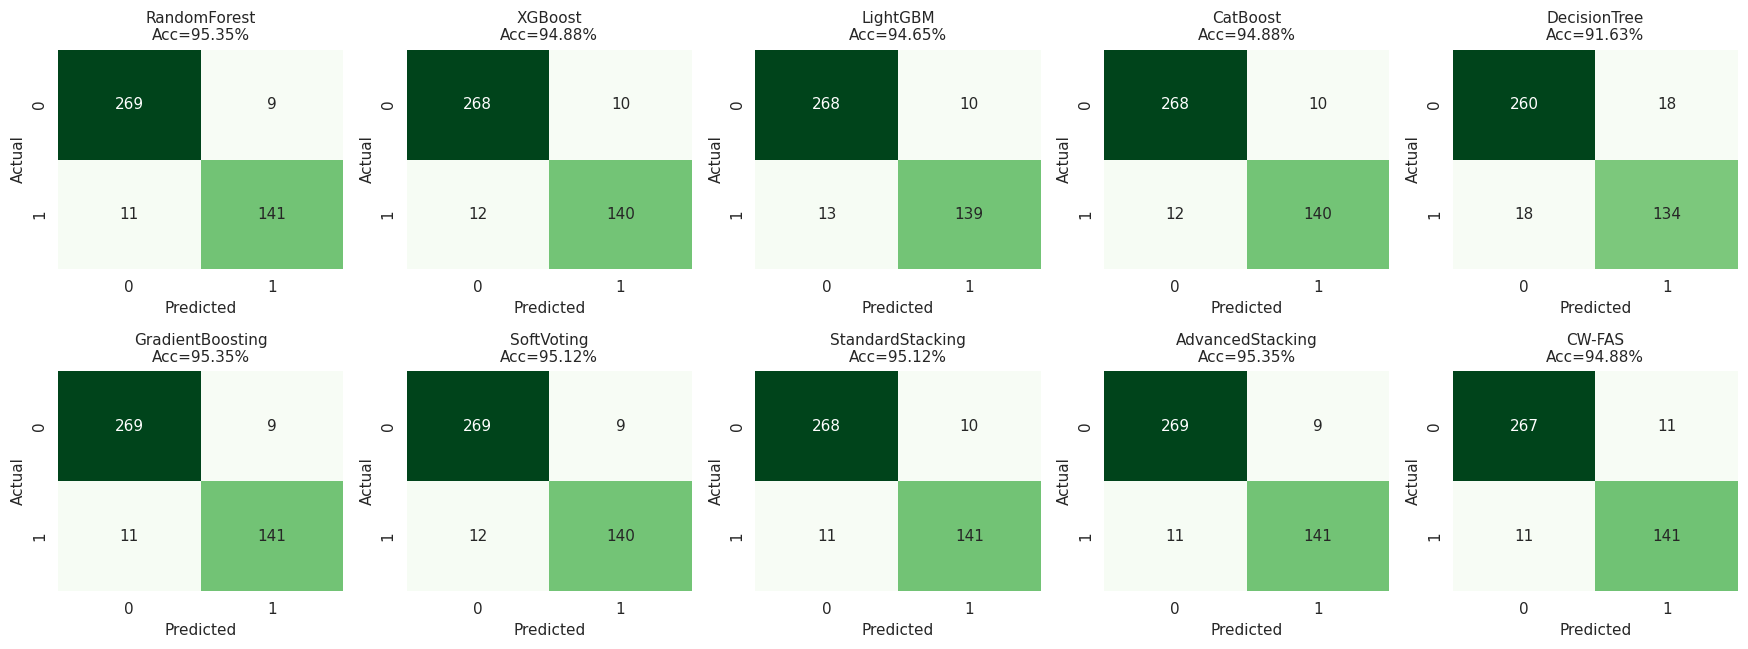

In [61]:
def plot_confusion_grid(probs_dict, y_true, threshold=0.50,
                        ncols=5, savepath="confusion_matrices_v3.png"):
    models = list(probs_dict.keys())
    nrows = int(np.ceil(len(models) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.0 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, m in zip(axes, models):
        y_pred = (probs_dict[m] >= threshold).astype(int)
        cm = confusion_matrix(y_true, y_pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax,
                    xticklabels=["0", "1"], yticklabels=["0", "1"])
        acc = cm.diagonal().sum() / cm.sum()
        ax.set_title(f"{m}\nAcc={acc*100:.2f}%", fontsize=10)
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    for ax in axes[len(models):]:
        ax.axis("off")
    plt.tight_layout(); plt.savefig(savepath, dpi=300, bbox_inches="tight")
    plt.show()

plot_confusion_grid(test_probs, y_test.values)

# **Cell 19: ROC and PR Curves (All Models)**

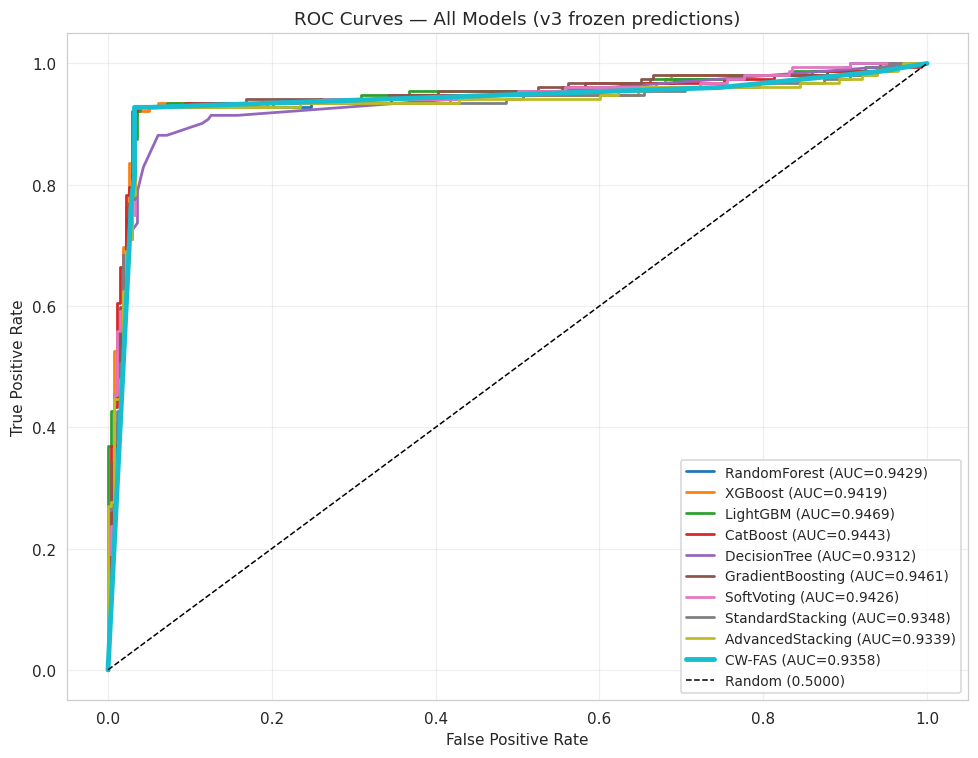

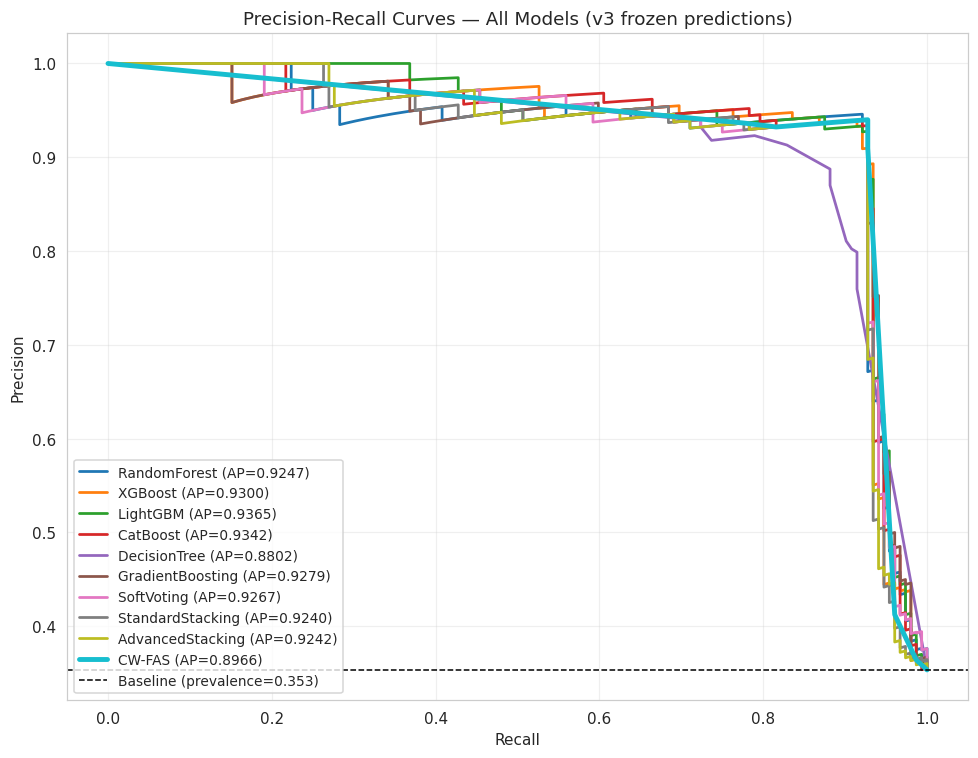

In [62]:
colors = plt.cm.tab10(np.linspace(0, 1, len(MODEL_NAMES)))

# ROC
fig, ax = plt.subplots(figsize=(9, 7))
for color, m in zip(colors, MODEL_NAMES):
    fpr, tpr, _ = roc_curve(y_test.values, test_probs[m])
    auc = roc_auc_score(y_test.values, test_probs[m])
    lw = 3.2 if m == "CW-FAS" else 1.8
    ax.plot(fpr, tpr, color=color, lw=lw, label=f"{m} (AUC={auc:.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random (0.5000)")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — All Models (v3 frozen predictions)")
ax.legend(loc="lower right", fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("roc_v3.png", dpi=300, bbox_inches="tight")
plt.show()

# PR
fig, ax = plt.subplots(figsize=(9, 7))
prev = float(y_test.mean())
for color, m in zip(colors, MODEL_NAMES):
    prec, rec, _ = precision_recall_curve(y_test.values, test_probs[m])
    ap = average_precision_score(y_test.values, test_probs[m])
    lw = 3.2 if m == "CW-FAS" else 1.8
    ax.plot(rec, prec, color=color, lw=lw, label=f"{m} (AP={ap:.4f})")
ax.axhline(prev, color="k", ls="--", lw=1,
           label=f"Baseline (prevalence={prev:.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curves — All Models (v3 frozen predictions)")
ax.legend(loc="lower left", fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("pr_v3.png", dpi=300, bbox_inches="tight")
plt.show()

# **Cell 20: CW-FAS Operating Point Overlay**

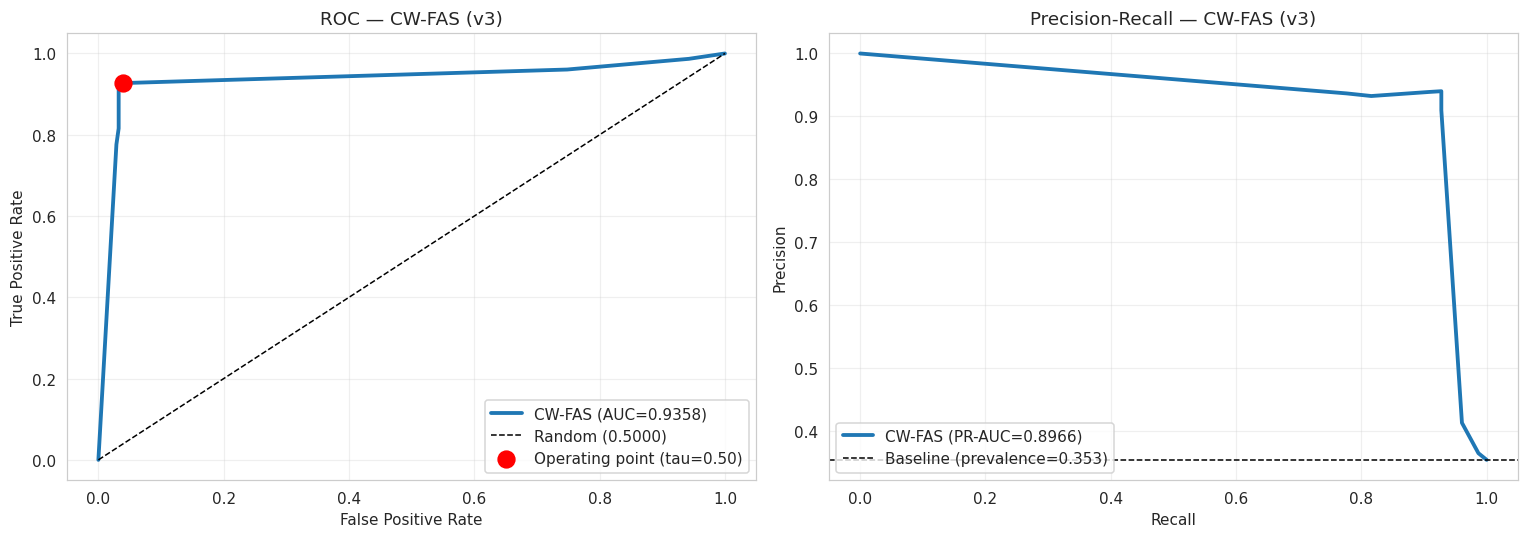

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fpr, tpr, _ = roc_curve(y_test.values, test_probs["CW-FAS"])
axes[0].plot(fpr, tpr, lw=2.5, color="tab:blue",
             label=f"CW-FAS (AUC={metrics_all['CW-FAS']['ROC-AUC']:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random (0.5000)")
axes[0].scatter(
    metrics_all["CW-FAS"]["FP"] / (metrics_all["CW-FAS"]["FP"] + metrics_all["CW-FAS"]["TN"]),
    metrics_all["CW-FAS"]["TP"] / (metrics_all["CW-FAS"]["TP"] + metrics_all["CW-FAS"]["FN"]),
    color="red", s=120, zorder=5, label="Operating point (tau=0.50)"
)
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC — CW-FAS (v3)")
axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

prec, rec, _ = precision_recall_curve(y_test.values, test_probs["CW-FAS"])
axes[1].plot(rec, prec, lw=2.5, color="tab:blue",
             label=f"CW-FAS (PR-AUC={metrics_all['CW-FAS']['PR-AUC']:.4f})")
axes[1].axhline(prev, color="k", ls="--", lw=1,
                label=f"Baseline (prevalence={prev:.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall — CW-FAS (v3)")
axes[1].legend(loc="lower left"); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.savefig("cwfas_v3_roc_pr.png", dpi=300, bbox_inches="tight")
plt.show()

# **Cell 21: Feature Importance**

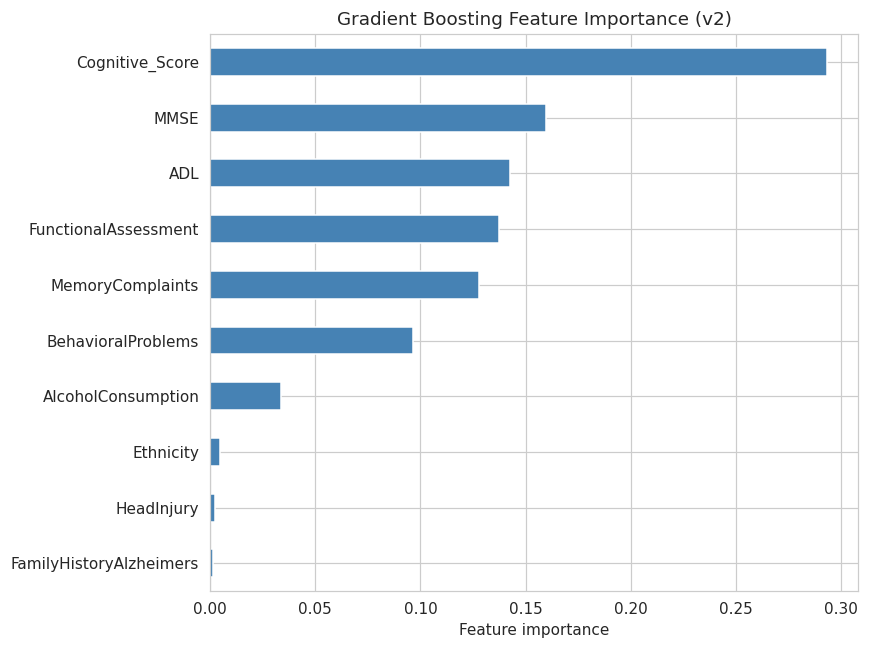

In [64]:
gb = GradientBoostingClassifier(n_estimators=600, learning_rate=0.05,
                                max_depth=5, subsample=0.8, random_state=SEED)
gb.fit(X_dev[final_features], y_dev)
imp = pd.Series(gb.feature_importances_, index=final_features).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
imp.plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("Feature importance")
ax.set_title("Gradient Boosting Feature Importance (v2)")
plt.tight_layout(); plt.savefig("feature_importance_v2.png", dpi=300, bbox_inches="tight")
plt.show()

# **Cell 22: CV Accuracy Bar Chart**

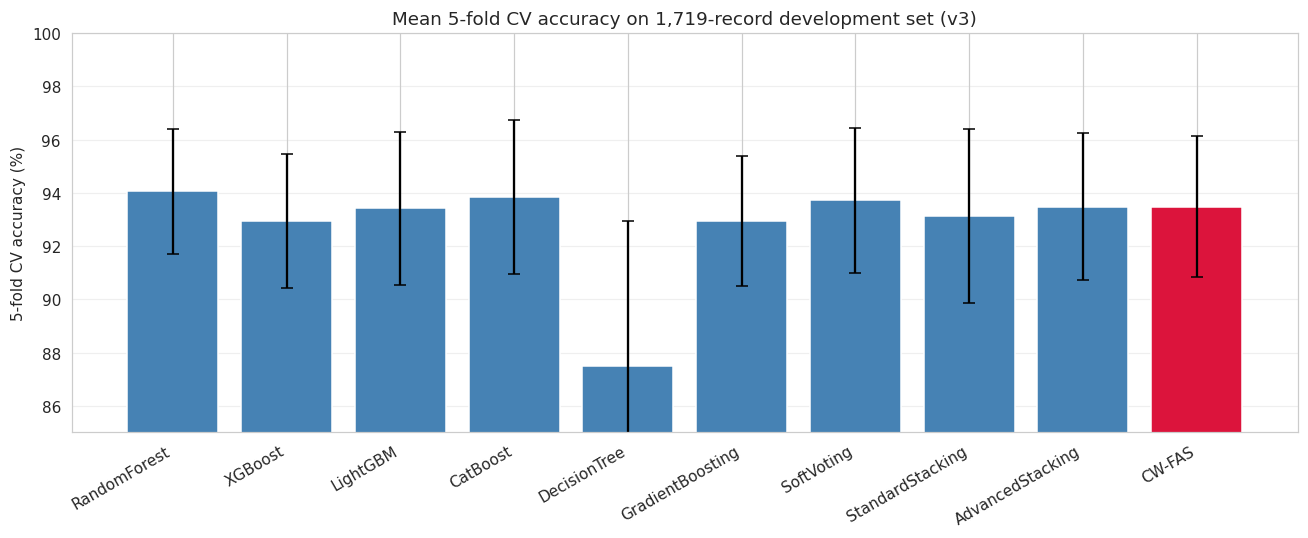

In [65]:
fig, ax = plt.subplots(figsize=(12, 5))
avgs = [np.mean(cv_acc[m]) * 100 for m in MODEL_NAMES]
stds = [np.std(cv_acc[m]) * 100 for m in MODEL_NAMES]
cols = ["crimson" if m == "CW-FAS" else "steelblue" for m in MODEL_NAMES]
ax.bar(MODEL_NAMES, avgs, yerr=stds, color=cols, capsize=4)
ax.set_ylabel("5-fold CV accuracy (%)")
ax.set_title("Mean 5-fold CV accuracy on 1,719-record development set (v3)")
plt.xticks(rotation=30, ha="right"); plt.ylim(85, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("cv_accuracy_bar_v3.png", dpi=300, bbox_inches="tight")
plt.show()